# Module End  Assignment: Python For Data Analysis

## Social Media Engagement Analytics

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import plotly.express as px

df = pd.read_csv(r'C:\Users\DELL\Documents\Entri data analytics\Python\Module End  Assignment Python For Data Analysis\social_media_engagement_5000.csv')
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [4]:
# Inspection and Properties
print("Shape:", df.shape)
print("Data Types:\n", df.dtypes)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Shape: (5000, 19)
Data Types:
 user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object
Number of Rows: 5000
Number of Columns: 19


In [7]:
# Date Conversion
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y',
    errors='coerce')
print("Date Data Type:", df['posted_at'].dtype)
df['posted_at'].dtype

Date Data Type: datetime64[ns]


dtype('<M8[ns]')

In [8]:
# NumPy Array Operations
likes = np.array(df['likes'])

print("Likes Array:", likes)
print("Maximum Likes:", np.max(likes))
print("Minimum Likes:", np.min(likes))
print("Mean Likes:", np.mean(likes))
print("Total Likes:", np.sum(likes))

Likes Array: [ 7011. 11750.  4862. ... 13487. 16894. 14830.]
Maximum Likes: nan
Minimum Likes: nan
Mean Likes: nan
Total Likes: nan


In [9]:
# TASK 2: DATA CLEANING
# Missing Value Inspection
print("Missing Values:\n", df.isnull().sum())
print("Total Missing Values:", df.isnull().sum().sum())
print("Missing Values using isna():\n", df.isna().sum())

Missing Values:
 user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64
Total Missing Values: 900
Missing Values using isna():
 user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dt

In [10]:
# Duplicate Handling
print("Duplicates Before Cleaning:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicates After Cleaning:", df.duplicated().sum())

Duplicates Before Cleaning: 0
Duplicates After Cleaning: 0


In [11]:
# Fill Missing Numerical Values
numeric_columns = df.select_dtypes(include=np.number).columns
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())
print("Missing Numerical Values:\n", df[numeric_columns].isnull().sum())

Missing Numerical Values:
 user_id             0
age                 0
post_id             0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
follower_count      0
engagement_rate     0
dtype: int64


In [12]:
# Fill Missing Categorical Values
categorical_columns = df.select_dtypes(include='object').columns
for col in categorical_columns:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])
print("Missing Categorical Values:\n", df[categorical_columns].isnull().sum())

Missing Categorical Values:
 gender           0
country          0
post_type        0
post_category    0
device_type      0
sentiment        0
hashtags         0
dtype: int64


In [13]:
# Standardize Text Values
for col in categorical_columns:
    df[col] = df[col].str.strip().str.lower()
print("Standardized Gender:\n", df['gender'].unique())
print("Standardized Post Types:\n", df['post_type'].unique())
print("Standardized Sentiments:\n", df['sentiment'].unique())

Standardized Gender:
 ['female' 'male' 'other']
Standardized Post Types:
 ['image' 'reel' 'text' 'video']
Standardized Sentiments:
 ['negative' 'positive' 'neutral']


In [14]:
# Correct Negative Values
count_columns = ['likes', 'comments', 'shares',
    'watch_time_sec', 'impression_count', 'follower_count']
for col in count_columns:
    df.loc[df[col] < 0, col] = np.nan
    df[col] = df[col].fillna(df[col].median())
print("Negative Values After Cleaning:")
for col in count_columns:
    print(col, ":", (df[col] < 0).sum())

Negative Values After Cleaning:
likes : 0
comments : 0
shares : 0
watch_time_sec : 0
impression_count : 0
follower_count : 0


In [15]:
# Hashtag Count
df['hashtag_count'] = df['hashtags'].apply(
    lambda x: len(str(x).split()))
print("Hashtag Count:")
display(df[['hashtags', 'hashtag_count']].head())

Hashtag Count:


,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


In [16]:
# Sentiment Cleaning
df['sentiment'] = df['sentiment'].str.strip().str.lower()
df['sentiment'] = df['sentiment'].replace({
    'pos': 'positive',
    'neg': 'negative',
    'neu': 'neutral'})
print("Sentiment Categories:")
print(df['sentiment'].value_counts())

Sentiment Categories:
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64


In [23]:
print("First 5 Rows:\n", df.head())
print("\nLast 5 Rows:\n", df.tail())
print("\nDataset Shape:", df.shape)
print("\nColumn Names:\n", df.columns)

First 5 Rows:
    user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  female      UK   109864      text          food   4862.0   
3    64886  51.0   other  France   848877      text       fitness   5350.0   
4    16265  34.0   other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count   posted_at  \
0     354.0  1157.0            5726             44650  17-12-2022   
1    2606.0  1807.0            5947             80216  02-06-2023   
2     344.0   955.0            6946             44858  07-05-2023   
3    1083.0  1049.0             229             70455  12-02-2023   
4    2735.0  1300.0            4798              6019  23-05-2023   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734     

In [24]:
df.info()
print("\nData Types:\n", df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               5000 non-null   float64
 2   gender            5000 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             5000 non-null   float64
 8   comments          5000 non-null   float64
 9   shares            5000 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         5000 non-null   object 


In [17]:
# Summary Statistics
print("Descriptive Statistics:")
display(df.describe())

Descriptive Statistics:


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [21]:
# Categorical Distribution
print("Gender Distribution:\n", df['gender'].value_counts())
print("\nPost Type Distribution:\n", df['post_type'].value_counts())
print("\nCategory Distribution:\n", df['post_category'].value_counts())
print("\nSentiment Distribution:\n", df['sentiment'].value_counts())

Gender Distribution:
 gender
male      1849
other     1581
female    1570
Name: count, dtype: int64

Post Type Distribution:
 post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

Category Distribution:
 post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64

Sentiment Distribution:
 sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64


In [22]:
# Unique Values
print("Unique Countries:", df['country'].unique())
print("Unique Post Types:", df['post_type'].unique())
print("Unique Devices:", df['device_type'].unique())

Unique Countries: ['Brazil' 'UK' 'France' 'Canada' 'Japan' 'Australia' 'India' 'UAE'
 'Germany' 'USA']
Unique Post Types: ['image' 'reel' 'text' 'video']
Unique Devices: ['mobile' 'tablet' 'desktop']


In [25]:
# Number of Unique Values
print("Countries:", df['country'].nunique())
print("Post Types:", df['post_type'].nunique())
print("Post Categories:", df['post_category'].nunique())
print("Devices:", df['device_type'].nunique())

Countries: 10
Post Types: 4
Post Categories: 8
Devices: 3


In [26]:
# Correlation Matrix
numeric_data = df.select_dtypes(include=np.number)
correlation_matrix = numeric_data.corr()
print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


In [27]:
# Groupby Post Type
print("Average Engagement by Post Type:")

display(df.groupby('post_type')[
    ['likes', 'comments', 'shares', 'engagement_rate']
].mean())

Average Engagement by Post Type:


,likes,comments,shares,engagement_rate
post_type,,,,
image,10104.865277,1525.235766,1019.289495,0.895646
reel,10037.802416,1504.187062,982.042089,0.783047
text,10100.148193,1499.106024,1013.989558,1.064549
video,10188.600000,1479.160000,996.834286,1.122365


In [28]:
# Groupby Country
print("Average Impressions by Country:")

display(df.groupby('country')['impression_count']
        .mean().sort_values(ascending=False))

Average Impressions by Country:


country
India        52462.386916
France       51727.673387
USA          51263.872255
UK           51119.393509
Japan        49616.135593
Brazil       49193.174603
UAE          48928.413519
Canada       48703.150097
Germany      48605.406122
Australia    48346.383367
Name: impression_count, dtype: float64

In [30]:
# Task 4: Data Wrangling

# Engagement Score
df['engagement_score'] = (
    df['likes'] + df['comments'] + df['shares'])
print("Engagement Score:")
display(df[['likes', 'comments', 'shares', 'engagement_score']].head())

Engagement Score:


,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


In [31]:
# Log Transformation

df['log_likes'] = np.log1p(df['likes'])
df['log_comments'] = np.log1p(df['comments'])
df['log_shares'] = np.log1p(df['shares'])
print("Log Transformed Metrics:")
display(df[['log_likes', 'log_comments', 'log_shares']].head())

Log Transformed Metrics:


,log_likes,log_comments,log_shares
0,8.855378,5.872118,7.054450
1,9.371694,7.865955,7.499977
2,8.489411,5.843544,6.862758
3,8.585039,6.988413,6.956545
4,9.448018,7.914252,7.170888


In [32]:
# Hashtag Count
df['hashtag_count'] = df['hashtags'].apply(
    lambda x: len(str(x).split()))
print("Hashtag Count:")
display(df[['hashtags', 'hashtag_count']].head())

Hashtag Count:


,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


In [33]:
# Groupby Post Type
post_type_summary = df.groupby('post_type').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean',
    'engagement_rate': 'mean'})
print("Post Type Summary:")
display(post_type_summary)

Post Type Summary:


,likes,comments,shares,engagement_score,engagement_rate
post_type,,,,,
image,10104.865277,1525.235766,1019.289495,12649.390537,0.895646
reel,10037.802416,1504.187062,982.042089,12524.031567,0.783047
text,10100.148193,1499.106024,1013.989558,12613.243775,1.064549
video,10188.600000,1479.160000,996.834286,12664.594286,1.122365


In [34]:
# Groupby Country

country_summary = df.groupby('country').agg({
    'likes': 'mean',
    'impression_count': 'mean',
    'engagement_score': 'mean',
    'engagement_rate': 'mean'})
print("Country Summary:")
display(country_summary)

Country Summary:


,likes,impression_count,engagement_score,engagement_rate
country,,,,
Australia,10294.124746,48346.383367,12809.621704,1.324339
Brazil,9886.689484,49193.174603,12385.983135,1.540704
Canada,10063.066277,48703.150097,12605.894737,0.916659
France,10372.876008,51727.673387,12903.384073,1.146402
Germany,10130.458163,48605.406122,12635.664286,0.759000
India,9962.468224,52462.386916,12492.701869,0.655005
Japan,10088.862288,49616.135593,12578.648305,0.769623
UAE,10227.487078,48928.413519,12757.777336,1.112352
UK,9935.650101,51119.393509,12384.374239,0.850966


In [35]:
# Groupby Sentiment

sentiment_summary = df.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean',
    'engagement_rate': 'mean'})
print("Sentiment Summary:")
display(sentiment_summary)

Sentiment Summary:


,likes,comments,shares,engagement_score,engagement_rate
sentiment,,,,,
negative,10208.096875,1516.094792,1007.307292,12731.498958,1.038486
neutral,9923.194499,1528.404060,996.565160,12448.163720,0.991170
positive,10180.062077,1480.650617,1005.086749,12665.799443,0.919744


In [36]:
# Merge DataFrames

country_engagement = df.groupby('country', as_index=False).agg({
    'engagement_rate': 'mean'})
country_engagement.rename(
    columns={'engagement_rate': 'average_engagement'},
    inplace=True)
merged_data = pd.merge(
    df,
    country_engagement,
    on='country',
    how='left')
print("Merged DataFrame:")
display(merged_data[['country', 'engagement_rate',
                     'average_engagement']].head())

Merged DataFrame:


,country,engagement_rate,average_engagement
0,Brazil,0.190862,1.540704
1,Brazil,0.201493,1.540704
2,UK,0.137345,0.850966
3,France,0.106195,1.146402
4,UK,2.777372,0.850966


In [37]:
# Concatenate DataFrames

df1 = df.iloc[:2500]
df2 = df.iloc[2500:]
combined_data = pd.concat([df1, df2], ignore_index=True)
print("Original Dataset Shape:", df.shape)
print("Combined Dataset Shape:", combined_data.shape)
display(combined_data.head())

Original Dataset Shape: (5000, 24)
Combined Dataset Shape: (5000, 24)


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,log_likes,log_comments,log_shares
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,...,False,mobile,negative,#foodie #travel #love,0.190862,3,8522.0,8.855378,5.872118,7.054450
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,...,False,mobile,negative,#fitness,0.201493,1,16163.0,9.371694,7.865955,7.499977
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,...,False,tablet,positive,#foodie,0.137345,1,6161.0,8.489411,5.843544,6.862758
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,...,False,mobile,negative,#music #foodie #fun,0.106195,3,7482.0,8.585039,6.988413,6.956545
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,...,False,mobile,negative,#travel,2.777372,1,16717.0,9.448018,7.914252,7.170888


In [38]:
# Task 5: Statistical Analysis

# Descriptive Statistics

stats_columns = ['likes', 'comments', 'shares','watch_time_sec', 'engagement_rate', 'follower_count']
for col in stats_columns:
    print("\nColumn:", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])


Column: likes
Mean: 10106.9974
Median: 10105.5
Mode: 10105.5

Column: comments
Mean: 1502.0398
Median: 1497.0
Mode: 1497.0

Column: shares
Mean: 1002.9106
Median: 1012.0
Mode: 1012.0

Column: watch_time_sec
Mean: 4014.5032
Median: 4034.5
Mode: 916

Column: engagement_rate
Mean: 0.9643560291583999
Median: 0.2538959065
Mode: 0.006362909

Column: follower_count
Mean: 393698.2248
Median: 388982.0
Mode: 497502


In [39]:
# Standard Deviation and Variance

for col in stats_columns:
    print("\nColumn:", col)
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())


Column: likes
Standard Deviation: 5702.293017183876
Variance: 32516145.653823998

Column: comments
Standard Deviation: 856.3933120458967
Variance: 733409.5049169405

Column: shares
Standard Deviation: 570.8551999758862
Variance: 325875.65933950903

Column: watch_time_sec
Standard Deviation: 2308.096459042085
Variance: 5327309.26424261

Column: engagement_rate
Standard Deviation: 5.318029222661535
Variance: 28.281434813082043

Column: follower_count
Standard Deviation: 230927.88453461014
Variance: 53327687855.63023


In [40]:
# Percentile Analysis

for col in stats_columns:
    print("\nColumn:", col)
    print("25th Percentile:", df[col].quantile(0.25))
    print("50th Percentile:", df[col].quantile(0.50))
    print("75th Percentile:", df[col].quantile(0.75))


Column: likes
25th Percentile: 5235.0
50th Percentile: 10105.5
75th Percentile: 14959.0

Column: comments
25th Percentile: 792.0
50th Percentile: 1497.0
75th Percentile: 2235.25

Column: shares
25th Percentile: 511.0
50th Percentile: 1012.0
75th Percentile: 1483.0

Column: watch_time_sec
25th Percentile: 2017.75
50th Percentile: 4034.5
75th Percentile: 6020.25

Column: engagement_rate
25th Percentile: 0.14578108750000002
50th Percentile: 0.2538959065
75th Percentile: 0.504793702

Column: follower_count
25th Percentile: 194480.0
50th Percentile: 388982.0
75th Percentile: 589744.25


In [41]:
# Skewness and Kurtosis

for col in stats_columns:
    print("\nColumn:", col)
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())


Column: likes
Skewness: -0.006893616532184278
Kurtosis: -1.1499923609078424

Column: comments
Skewness: 0.0038017289479831415
Kurtosis: -1.1443748352968992

Column: shares
Skewness: -0.014653583910311461
Kurtosis: -1.1468565626589917

Column: watch_time_sec
Skewness: -0.018196273193231846
Kurtosis: -1.195651797070188

Column: engagement_rate
Skewness: 18.781270878869154
Kurtosis: 482.9917386319569

Column: follower_count
Skewness: 0.04111777394961326
Kurtosis: -1.1894740478821386


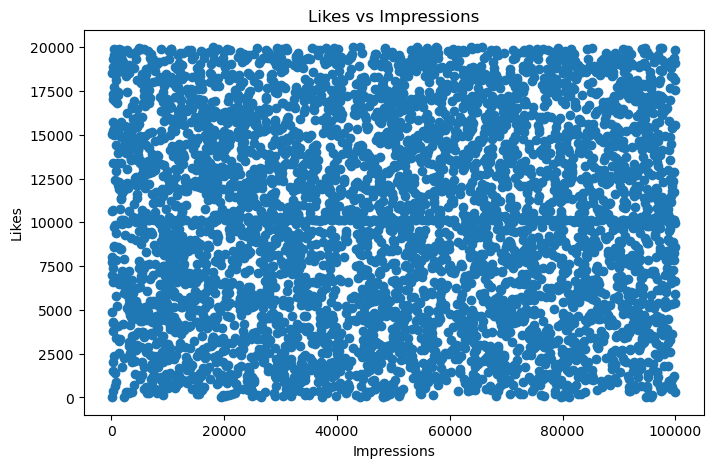

In [42]:
# Task 6 — Data Visualization

# Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(df['impression_count'], df['likes'])
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.title("Likes vs Impressions")
plt.show()

Data Type: datetime64[ns]


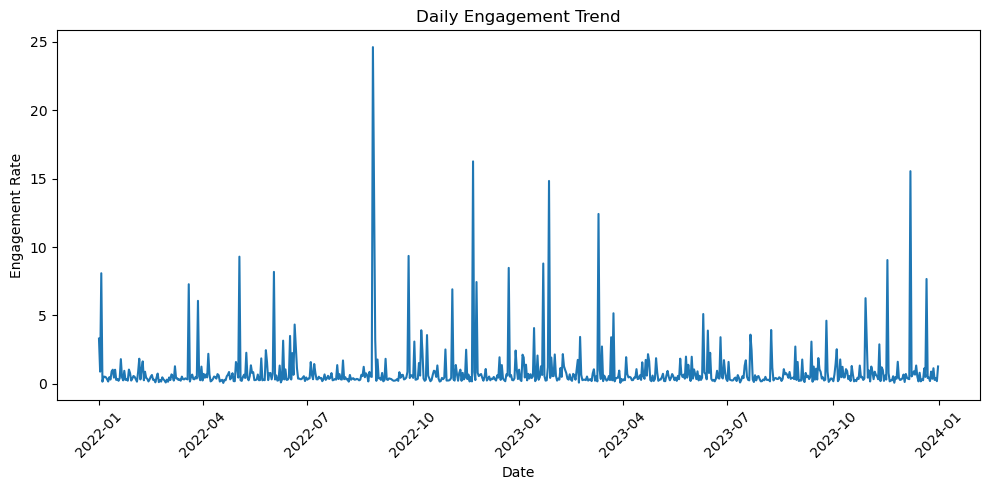

In [69]:
# Line Plot
# Convert Date Column to Datetime
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y',
    errors='coerce')

print("Data Type:", df['posted_at'].dtype)
daily_engagement = df.groupby(
    df['posted_at'].dt.date
)['engagement_rate'].mean()
plt.figure(figsize=(10, 5))
plt.plot(daily_engagement.index, daily_engagement.values)
plt.xlabel("Date")
plt.ylabel("Engagement Rate")
plt.title("Daily Engagement Trend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

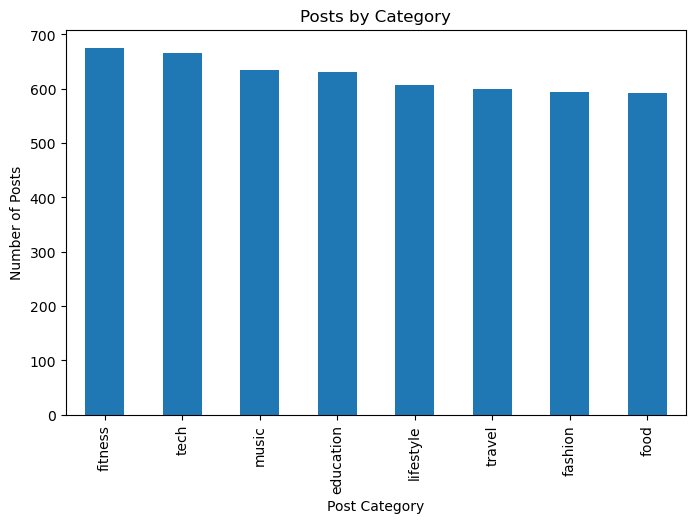

In [68]:
# Bar Chart
df['post_category'].value_counts().plot(kind='bar', figsize=(8, 5))

plt.xlabel("Post Category")
plt.ylabel("Number of Posts")
plt.title("Posts by Category")

plt.show()

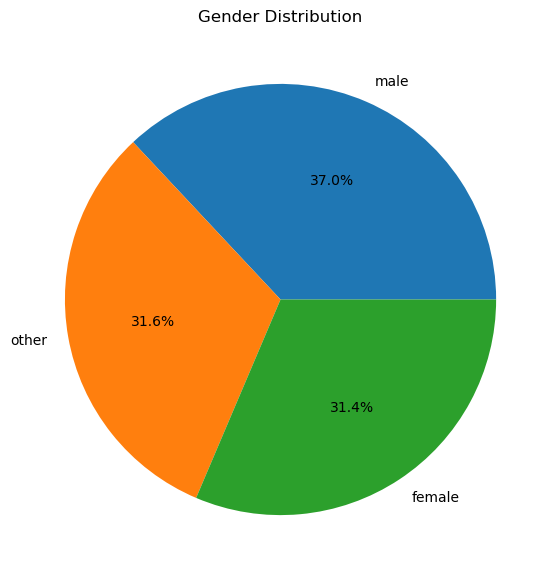

In [45]:
# Pie Chart
df['gender'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7, 7))
plt.title("Gender Distribution")
plt.ylabel("")
plt.show()

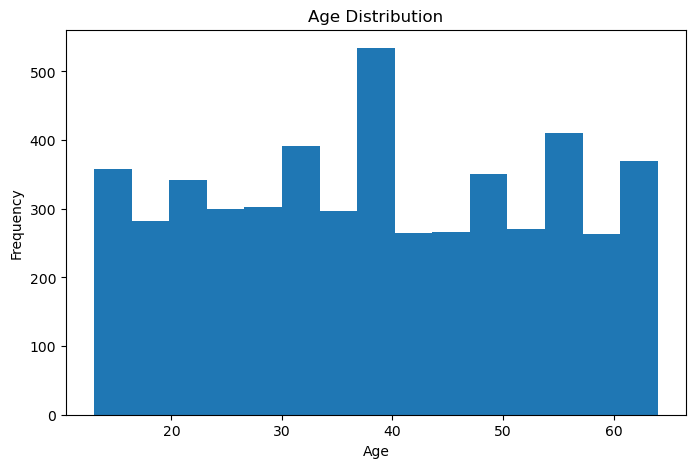

In [46]:
# Histogram
plt.figure(figsize=(8, 5))
plt.hist(df['age'], bins=15)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution")
plt.show()

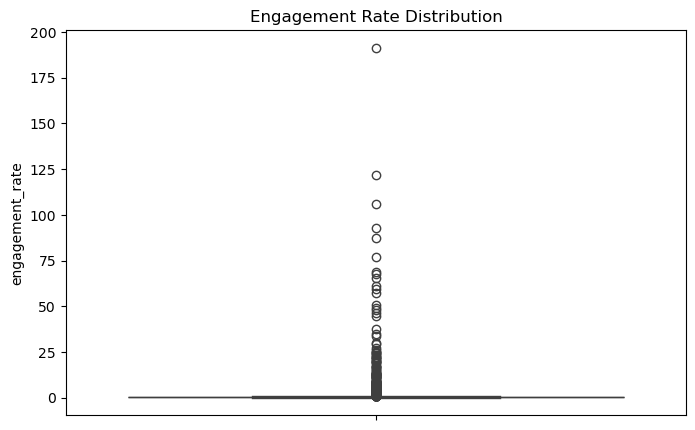

In [47]:
# Box Plot
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['engagement_rate'])
plt.title("Engagement Rate Distribution")
plt.show()

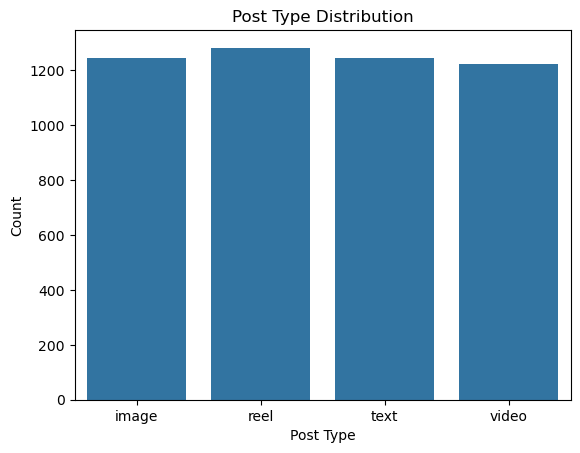

In [48]:
# Count Plot
sns.countplot(data=df, x='post_type')
plt.title("Post Type Distribution")
plt.xlabel("Post Type")
plt.ylabel("Count")
plt.show()

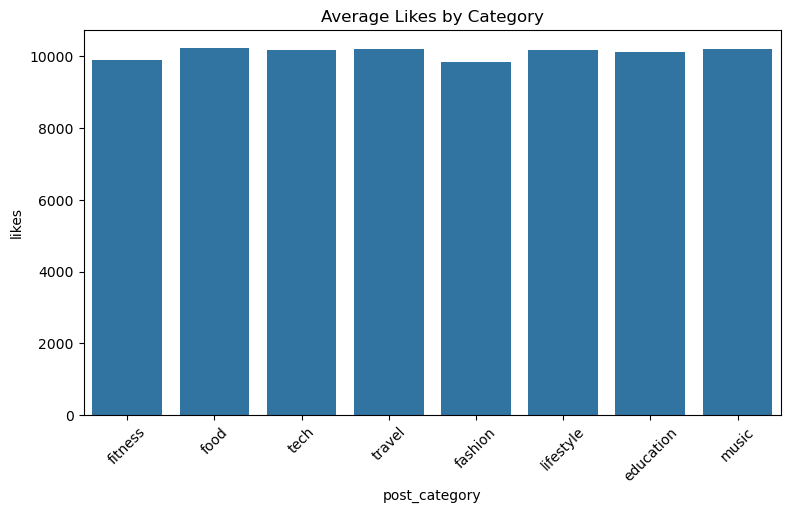

In [49]:
# Bar Plot
plt.figure(figsize=(9, 5))
sns.barplot(data=df,
    x='post_category',
    y='likes',
    errorbar=None)
plt.title("Average Likes by Category")
plt.xticks(rotation=45)
plt.show()

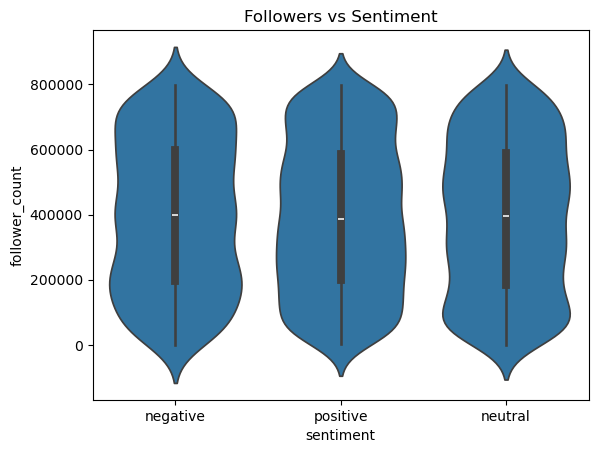

In [51]:
# Violin Plot
sns.violinplot(data=df,
    x='sentiment',
    y='follower_count')
plt.title("Followers vs Sentiment")
plt.show()

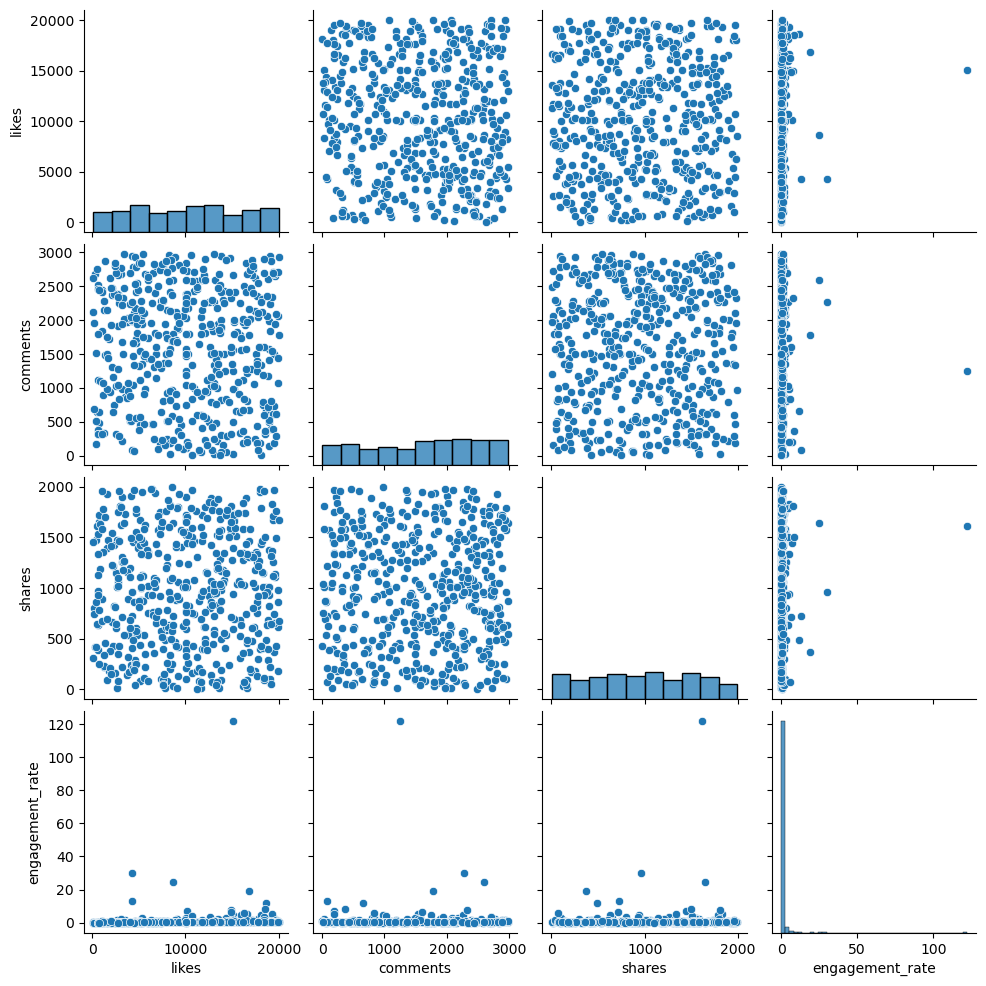

In [52]:
# Pair Plot
pair_data = df[
    ['likes', 'comments', 'shares', 'engagement_rate']
].sample(500, random_state=42)
sns.pairplot(pair_data)
plt.show()

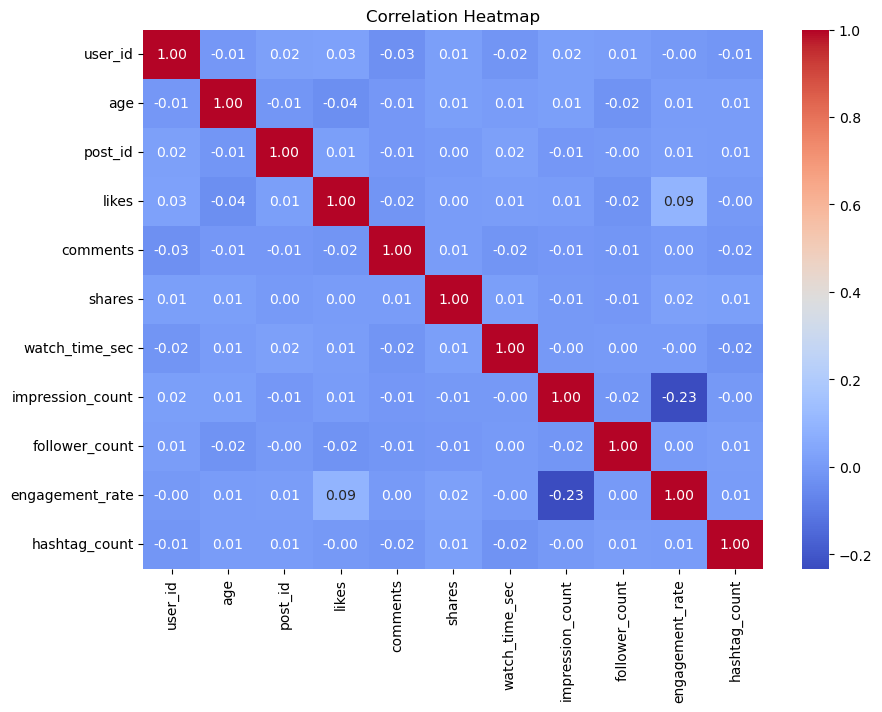

In [53]:
# Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

C:\Users\DELL\Documents\Python\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 25.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\DELL\Documents\Python\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 45.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\DELL\Documents\Python\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 42.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\DELL\Documents\Python\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 41.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\DELL\Documents\Python\Lib\site-packages\seaborn\categorical.py:3399: Us

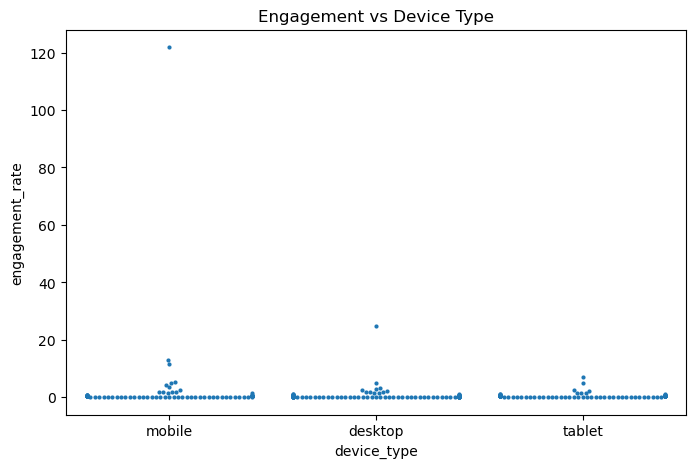

In [54]:
# Swarm Plot
swarm_data = df.sample(300, random_state=42)
plt.figure(figsize=(8, 5))
sns.swarmplot(data=swarm_data,
    x='device_type',
    y='engagement_rate',
    size=3)
plt.title("Engagement vs Device Type")
plt.show()

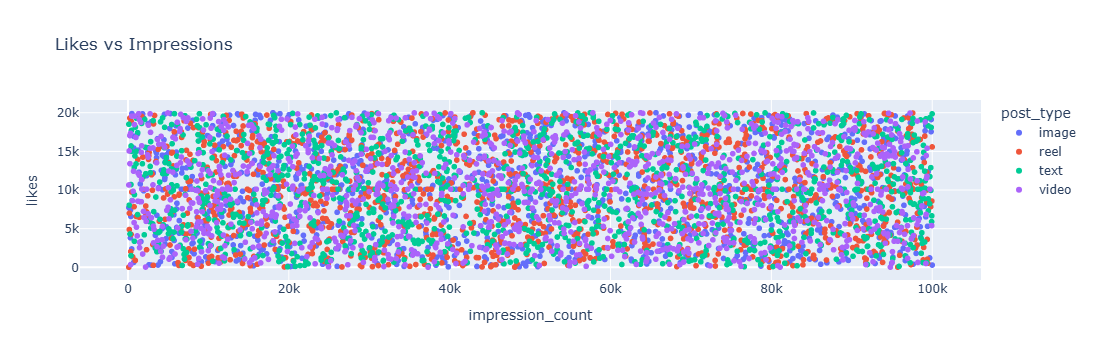

In [55]:
# Interactive Scatter Plot
fig = px.scatter(
    df,
    x='impression_count',
    y='likes',
    color='post_type',
    title='Likes vs Impressions')
fig.show()

In [58]:
# Highest Performing Post Type
post_performance = df.groupby('post_type')['engagement_rate'].mean()
print("Post Type Performance:")
display(post_performance.sort_values(ascending=False))
print("Best Post Type:", post_performance.idxmax())

Post Type Performance:


post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64

Best Post Type: video


In [59]:
# Best Performing Category
category_performance = df.groupby('post_category')['engagement_rate'].mean()
print("Category Performance:")
display(category_performance.sort_values(ascending=False))
print("Best Category:", category_performance.idxmax())

Category Performance:


post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64

Best Category: food


In [60]:
# Country Engagement
country_performance = df.groupby('country')['engagement_rate'].mean()
print("Country Performance:")
display(country_performance.sort_values(ascending=False))
print("Highest Engagement Country:", country_performance.idxmax())

Country Performance:


country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

Highest Engagement Country: Brazil


In [61]:
# Age Analysis
age_analysis = df.groupby('age')['engagement_rate'].mean()
print("Average Engagement by Age:")
display(age_analysis)

Average Engagement by Age:


age
13.0    0.455583
14.0    1.003067
15.0    0.714170
16.0    1.226848
17.0    0.858763
18.0    0.888391
19.0    0.676687
20.0    0.515541
21.0    0.452752
22.0    0.586786
23.0    0.922448
24.0    2.897327
25.0    1.041681
26.0    0.501467
27.0    0.775328
28.0    0.385081
29.0    1.110432
30.0    1.270129
31.0    0.440684
32.0    0.581710
33.0    1.277557
34.0    0.557236
35.0    1.521596
36.0    0.609569
37.0    0.494109
38.0    1.035114
39.0    0.436184
40.0    0.930504
41.0    1.540070
42.0    1.350772
43.0    0.566439
44.0    0.795102
45.0    0.513521
46.0    0.663994
47.0    1.402015
48.0    1.675878
49.0    0.999235
50.0    1.552627
51.0    2.397295
52.0    0.867426
53.0    0.707924
54.0    1.002622
55.0    2.599106
56.0    0.524008
57.0    0.919751
58.0    0.435130
59.0    0.495578
60.0    0.759586
61.0    0.553854
62.0    1.005127
63.0    1.303909
64.0    0.402533
Name: engagement_rate, dtype: float64

In [62]:
# Verified Account Analysis
verified_analysis = df.groupby('is_verified')[
    ['likes', 'comments', 'shares', 'engagement_rate']
].mean()
print("Verified Account Performance:")
display(verified_analysis)

Verified Account Performance:


,likes,comments,shares,engagement_rate
is_verified,,,,
False,10137.201129,1505.511401,1001.599292,0.954744
True,9824.533126,1469.573499,1015.173913,1.054250


In [63]:
# Posting Time Analysis
print("Date Column:", df['posted_at'].dtype)
print("The dataset contains posting dates but does not")
print("contain exact posting hours.")
print("Therefore, the best time of day cannot be determined.")

Date Column: object
The dataset contains posting dates but does not
contain exact posting hours.
Therefore, the best time of day cannot be determined.


In [64]:
# Device Analysis
device_analysis = df.groupby('device_type')['watch_time_sec'].mean()
print("Average Watch Time by Device:")
display(device_analysis.sort_values(ascending=False))

Average Watch Time by Device:


device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64

In [65]:
# Sentiment Performance
sentiment_analysis = df.groupby('sentiment')[
    ['likes', 'comments', 'shares', 'engagement_rate']
].mean()
print("Sentiment Analysis:")
display(sentiment_analysis)

Sentiment Analysis:


,likes,comments,shares,engagement_rate
sentiment,,,,
negative,10208.096875,1516.094792,1007.307292,1.038486
neutral,9923.194499,1528.404060,996.565160,0.991170
positive,10180.062077,1480.650617,1005.086749,0.919744
